<a href="https://colab.research.google.com/github/bfzeigler/svd-image-compression/blob/main/notebooks/04%20which%20images.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 4: Which Images Does the SVD Like?

Names: Bianca Zeigler


In [1]:
import os
import subprocess
import sys
import importlib

USER = "bfzeigler"
REPO = "svd-image-compression"

if os.path.exists(REPO):
    subprocess.run(
        ["git", "-C", REPO, "pull"],
        check=True
    )
else:
    subprocess.run(
        [
            "git", "clone",
            f"https://github.com/{USER}/{REPO}.git",
            REPO
        ],
        check=True
    )

src_path = os.path.abspath(f"{REPO}/src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

import compress
importlib.reload(compress)

from compress import (
    rank_k_approx,
    rel_error,
    predicted_error,
    compression_ratio
)

import numpy as np
import matplotlib.pyplot as plt

print("Functions imported successfully.")

Functions imported successfully.


This block of code is downloading and importing the functions from earlier milestones

In [2]:
def k_for_error(s, target):
    """Smallest positive k whose relative error meets the target."""
    for k in range(1, len(s) + 1):
        if predicted_error(s, k) <= target:
            return k

This function tests the ranks in a increasing order and returns the first one that meets the target error

In [3]:
N = 256

i, j = np.meshgrid(
    np.arange(N),
    np.arange(N),
    indexing="ij"
)


def stripes(angle, width=16):
    """Black and white stripes tilted by angle degrees."""
    t = np.deg2rad(angle)

    return 255.0 * (
        np.floor(
            (i * np.cos(t) + j * np.sin(t)) / width
        ) % 2
    )


rng = np.random.default_rng(0)

patterns = {
    "stripes, 0 deg": stripes(0),
    "stripes, 45 deg": stripes(45),
    "checkerboard": 255.0 * ((i // 32 + j // 32) % 2),
    "disk": 255.0 * (
        (i - N / 2) ** 2 + (j - N / 2) ** 2
        < (N / 3) ** 2
    ),
    "noise": rng.integers(
        0, 256, size=(N, N)
    ).astype(float)
}

Each image is a 256 x 256 matrix and the formulas create both horizontal and diagonal stripes, a disk, a checkerboard as well as a random noise

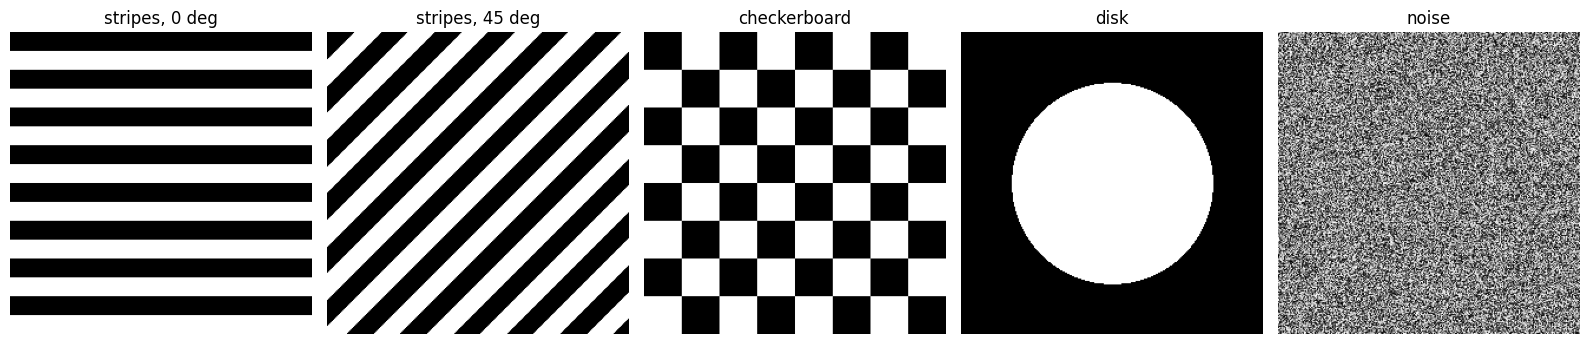

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for ax, (name, P) in zip(axes, patterns.items()):
    ax.imshow(P, cmap="gray", vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

Displaying the original images will allow me to compare the visible patterns before I compress the images

## Predictions

Horizontal stripes:
Predicted rank: 10

Diagonal stripes:
Predicted rank: 80

Checkerboard:
Predicted rank: 25

Disk:
Predicted rank: 40

Noise:
Predicted rank: 150

I think the horizonatal stripes will compress best because i think that image will have the lowest rank.

I think the noise will compress worst because i think that image will have the highest rank.

In [5]:
for name, P in patterns.items():
    s_pattern = np.linalg.svd(P, compute_uv=False)

    k5 = k_for_error(s_pattern, 0.05)

    print(
        f"{name:16s} "
        f"rank = {np.linalg.matrix_rank(P):3d} "
        f"k for 5% = {k5:3d} "
        f"ratio = {compression_ratio(N, N, k5):6.2f}"
    )

stripes, 0 deg   rank =   1 k for 5% =   1 ratio = 127.75
stripes, 45 deg  rank = 182 k for 5% =  64 ratio =   2.00
checkerboard     rank =   2 k for 5% =   2 ratio =  63.88
disk             rank =  51 k for 5% =  26 ratio =   4.91
noise            rank = 256 k for 5% = 198 ratio =   0.65


Unfortunatley none of my predictions were correct. I was the closest for the horizontal stripes and I was correct that I though the noise would have the highest rank.

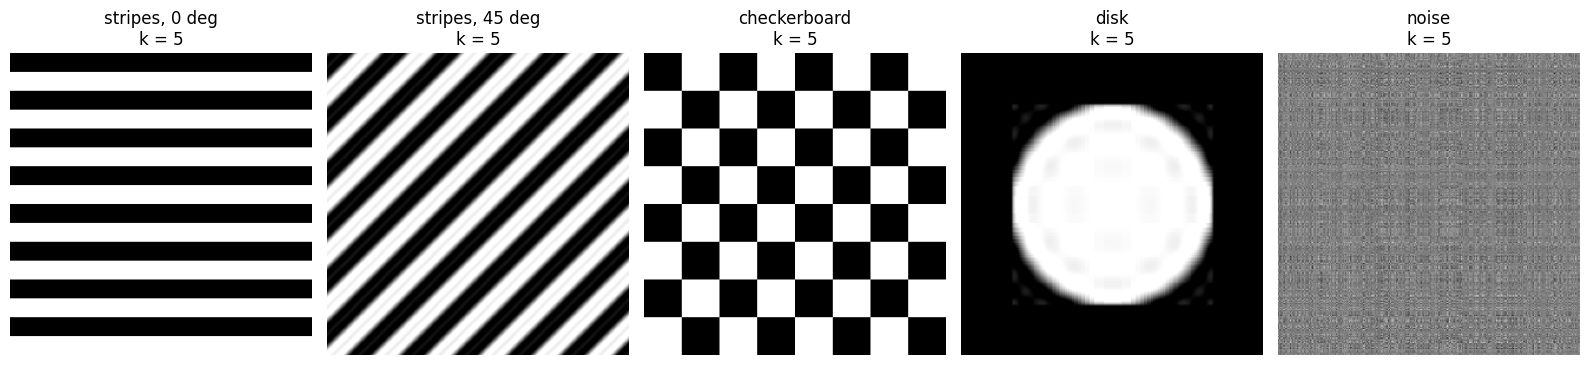

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for ax, (name, P) in zip(axes, patterns.items()):
    P5 = rank_k_approx(P, 5)

    ax.imshow(
        np.clip(P5, 0, 255),
        cmap="gray",
        vmin=0,
        vmax=255
    )

    ax.set_title(f"{name}\nk = 5")
    ax.axis("off")

plt.tight_layout()
plt.show()

The horizontal stripes and the checkerboard look essentially the exact same.
The diagonal stripes and the disk have lost a little bit of their detail.
Noise looks the worst out of all the images.

Angle =  0 degrees, k = 1
Angle =  5 degrees, k = 69
Angle = 10 degrees, k = 49
Angle = 15 degrees, k = 66
Angle = 20 degrees, k = 39
Angle = 25 degrees, k = 56
Angle = 30 degrees, k = 28
Angle = 35 degrees, k = 70
Angle = 40 degrees, k = 68
Angle = 45 degrees, k = 64
Angle = 50 degrees, k = 68
Angle = 55 degrees, k = 70
Angle = 60 degrees, k = 28
Angle = 65 degrees, k = 56
Angle = 70 degrees, k = 39
Angle = 75 degrees, k = 66
Angle = 80 degrees, k = 49
Angle = 85 degrees, k = 69
Angle = 90 degrees, k = 1


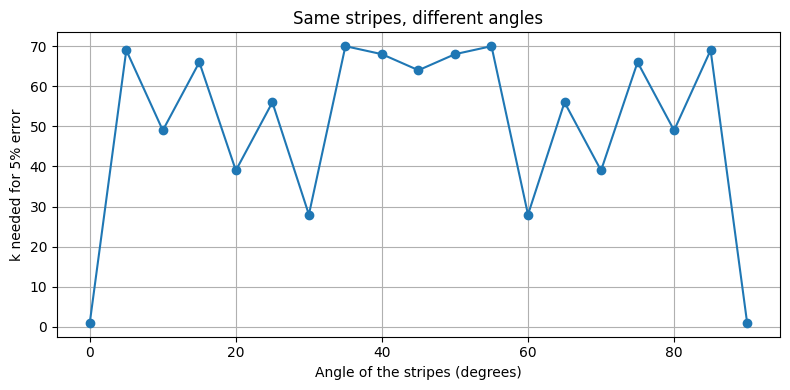

In [7]:
angles = np.arange(0, 91, 5)

ks = [
    k_for_error(
        np.linalg.svd(stripes(angle), compute_uv=False),
        0.05
    )
    for angle in angles
]

for angle, k in zip(angles, ks):
    print(f"Angle = {angle:2d} degrees, k = {k}")

plt.figure(figsize=(8, 4))
plt.plot(angles, ks, "o-")
plt.xlabel("Angle of the stripes (degrees)")
plt.ylabel("k needed for 5% error")
plt.title("Same stripes, different angles")
plt.grid()
plt.tight_layout()
plt.savefig("angles.png", dpi=150)
plt.show()

From this we can see that both horizontal and vertical stripes don't need that many terms. Titlting the stripes can shfit the pattern across the rows and increase the needed rank

## Exercise 1: Why are tilted stripes high rank?

In [8]:
print("Requested top-left corner:")
print(stripes(45)[:4, :12] / 255)

Requested top-left corner:
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


In [9]:
print("A region near a stripe boundary:")
print(stripes(45)[16:20, :12] / 255)

A region near a stripe boundary:
[[0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1.]
 [0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1.]
 [0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1.]
 [0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1.]]


As we move down the diagonal striped image, the stripe boundaries begin to shift sideways. The rows then have different patterns instead of being scalar multiples of one row. Therefore, increasing the rank.

##Exercise 2: Build two similar-looking images

I predict the horizontal stripe will compress better because it is a simpler pattern

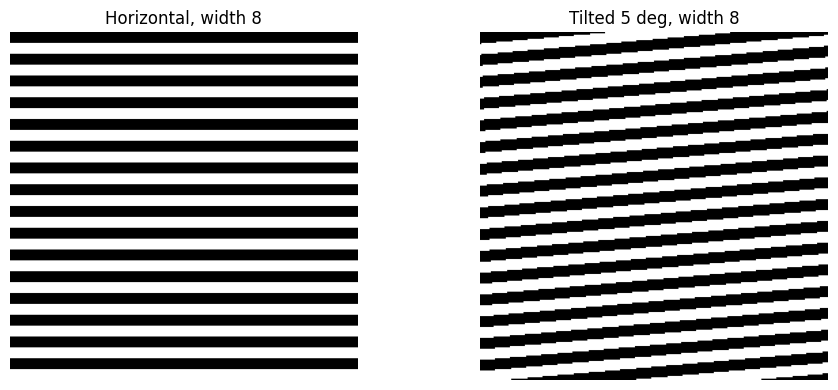

Horizontal, width 8: k for 5% = 1, ratio = 127.75
Tilted 5 deg, width 8: k for 5% = 67, ratio = 1.91


In [10]:
my_patterns = {
    "Horizontal, width 8": stripes(0, width=8),
    "Tilted 5 deg, width 8": stripes(5, width=8)
}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (name, M) in zip(axes, my_patterns.items()):
    ax.imshow(M, cmap="gray", vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

for name, M in my_patterns.items():
    s_custom = np.linalg.svd(M, compute_uv=False)
    k_custom = k_for_error(s_custom, 0.05)

    print(
        f"{name}: "
        f"k for 5% = {k_custom}, "
        f"ratio = "
        f"{compression_ratio(N, N, k_custom):.2f}"
    )

My prediction was correct. We can see clearly that the horizontal stripes has better alignment.

## Exercise 3: Color image compression

Original shape: (512, 512, 3)
Relative error before clipping: 7.87%


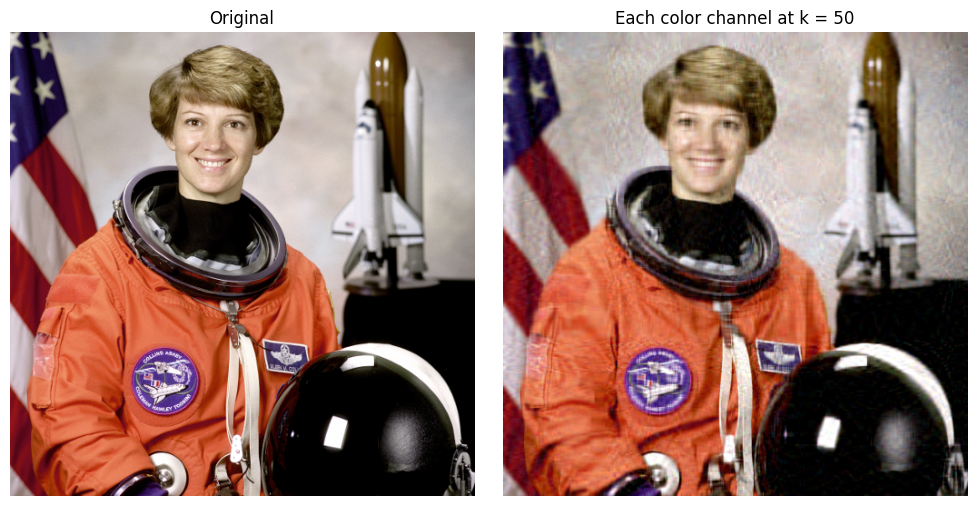

In [11]:
from skimage import data

C = data.astronaut()
C_float = C.astype(float)

k_color = 50

compressed_channels = [
    rank_k_approx(C_float[:, :, channel], k_color)
    for channel in range(3)
]

C_approx = np.stack(compressed_channels, axis=2)

color_error = rel_error(C_float, C_approx)

C_display = np.clip(
    C_approx, 0, 255
).astype(np.uint8)

print("Original shape:", C.shape)
print("Relative error before clipping:", f"{color_error:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(C)
axes[0].set_title("Original")

axes[1].imshow(C_display)
axes[1].set_title("Each color channel at k = 50")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
height, width, channels = C.shape

gray_storage = k_color * (height + width + 1)
color_storage = channels * gray_storage

print("Grayscale factor values:", gray_storage)
print("Color factor values:", color_storage)
print("Color / grayscale:", color_storage / gray_storage)

Grayscale factor values: 51250
Color factor values: 153750
Color / grayscale: 3.0


The relative error is 7.87%
The 3 channels are all compressed seprately and are then stacked back together.
The colors need 3x as many factor values as the grayscale for the exact same rank and dimenstions per channel.

## Exercise 4: Text image quality

Numerical error alone does not measure the readability of an image. We see this because most of a text image consists of background pixels. Matching the background can create a samll relative error. At rank = 5 the approximation can lose some of the finer detailes that are needed to distinguis letters.

## Main Finding

Tilting the horizontal stripes by 5 degrees increased the numbed of stored SVD values by a factor of 67 in order to stay within the same 5% relative error.

In [13]:
from google.colab import files

files.download("angles.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>